In [1]:
##################
### Keagan Moo ###
### 2025/02/27 ###
### RNA Break  ###
##################

# Script for loading in differential RNA results from MAST and DESeq2 for RNA-Enrich 
# runs via external Sartor lab code provided to me by Kai Wang from the Sartor lab
# DESeq2 enrichment lines are commented out and are not part of the paper

suppressPackageStartupMessages(library("glue"))
suppressPackageStartupMessages(library("tidyverse"))
suppressPackageStartupMessages(library("data.table"))
suppressPackageStartupMessages(library("org.Hs.eg.db"))
suppressPackageStartupMessages(library("annotate"))
suppressPackageStartupMessages(library("GO.db"))
suppressPackageStartupMessages(library("pheatmap"))
suppressPackageStartupMessages(library("hash"))
suppressPackageStartupMessages(library("KEGGREST"))
suppressPackageStartupMessages(library("limma"))

In [2]:
# Load in code from Sartor lab to run RNA-Enrich locally
source("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/externalScripts/LRpath_Final.r")

In [3]:
# Load in data for translation of gene symbols into entrez ids
cDex <- "Type_2a"

MASTRes <- read.csv(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/RNAEnrich/{cDex}_MAST_Total_GoExNom.csv"))
nrow(MASTRes)
MASTRes$ID <- mapIds(org.Hs.eg.db, keys = MASTRes$Symbol,
       column = "ENTREZID", keytype = "SYMBOL")
nrow(MASTRes)
#DESeqResF <- DESeqResF %>% dplyr::select(ID, pvalue, log2FoldChange)
MASTRes <- MASTRes %>% dplyr::select(ID, Pr..Chisq., coef)

#DESeqResF <- read.csv(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/RNAEnrich/{cDex}_DESEq2_Female_GoExNom.csv"))
MASTResF <- read.csv(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/RNAEnrich/{cDex}_MAST_Female_GoExNom.csv"))
#DESeqResF$ID <- mapIds(org.Hs.eg.db, keys = DESeqResF$Symbol,
#       column = "ENTREZID", keytype = "SYMBOL")
nrow(MASTResF)
MASTResF$ID <- mapIds(org.Hs.eg.db, keys = MASTResF$Symbol,
       column = "ENTREZID", keytype = "SYMBOL")
nrow(MASTResF)
#DESeqResF <- DESeqResF %>% dplyr::select(ID, pvalue, log2FoldChange)
MASTResF <- MASTResF %>% dplyr::select(ID, Pr..Chisq., coef)

#DESeqResM <- read.csv(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/RNAEnrich/{cDex}_DESEq2_Male_GoExNom.csv"))
MASTResM <- read.csv(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/RNAEnrich/{cDex}_MAST_Male_GoExNom.csv"))
#DESeqResM$ID <- mapIds(org.Hs.eg.db, keys = DESeqResM$Symbol,
#       column = "ENTREZID", keytype = "SYMBOL")
nrow(MASTResM)
MASTResM$ID <- mapIds(org.Hs.eg.db, keys = MASTResM$Symbol,
       column = "ENTREZID", keytype = "SYMBOL")
nrow(MASTResM)
#DESeqResM <- DESeqResM %>% dplyr::select(ID, pvalue, log2FoldChange)
MASTResM <- MASTResM %>% dplyr::select(ID, Pr..Chisq., coef)

[1] 5626

'select()' returned 1:1 mapping between keys and columns



[1] 5626

[1] 5453

'select()' returned 1:1 mapping between keys and columns



[1] 5453

[1] 5743

'select()' returned 1:1 mapping between keys and columns



[1] 5743

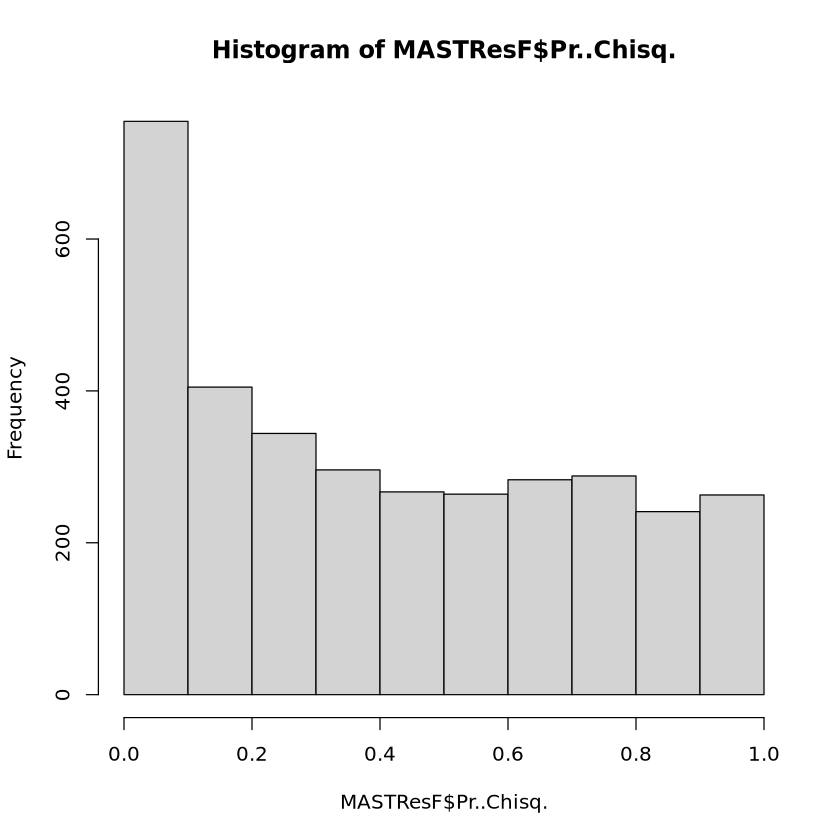

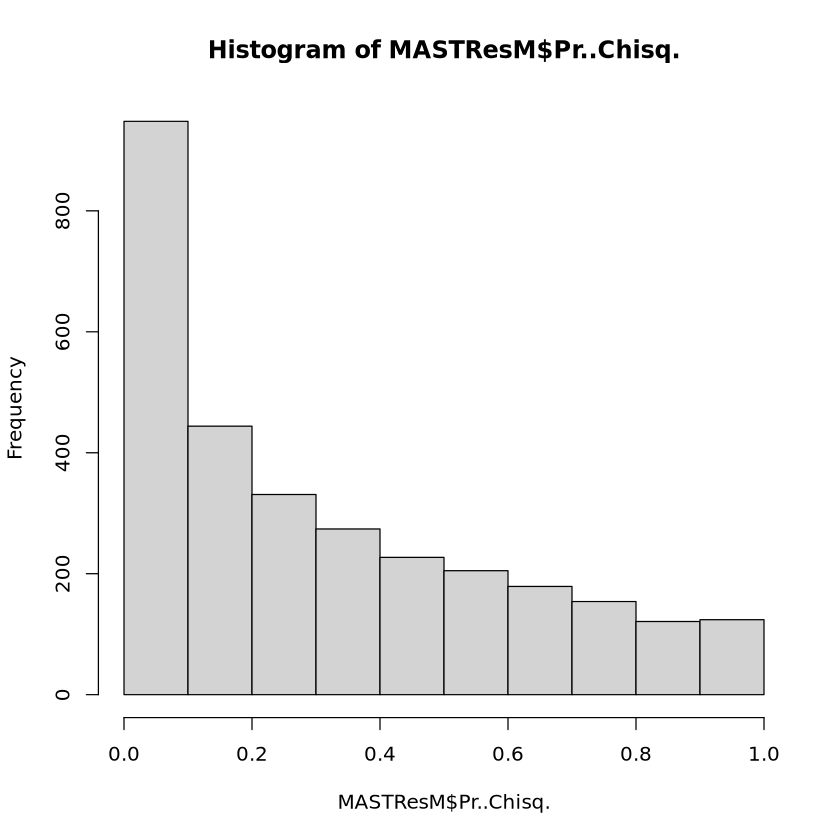

In [4]:
# Check on p-value distribution
hist(MASTResF$Pr..Chisq.)
hist(MASTResM$Pr..Chisq.)

In [4]:
# Run Sex combined enrichment test first, not part of the paper

MASTRes <- MASTRes[!(is.na(MASTRes$Pr..Chisq.) | is.na(MASTRes$coef)),]
inputt <- glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/RNAEnrich/{cDex}_MAST_Total_GoInNom.txt")
outputt_KEGG <- glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/RNAEnrich/{cDex}_MAST_Total_GoOutNom_KEGG.csv")

write.table(MASTRes, file = inputt, sep = " ", row.names = FALSE)
MASTResTOut_KEGG <- LRpath(inputt, species = "hsa", database = c("KEGG"))
MASTResTOut_KEGG$Type <- glue("{cDex}")
MASTResTOut_KEGG$Sex <- "Total"
write.csv(MASTResTOut_KEGG, file = outputt_KEGG)

[1] "10% categories finished."
[1] "20% categories finished."
[1] "50% categories finished."
[1] "90% categories finished."


In [21]:
# Run enrichment test for all other combinations next, DESeq2 and directional analyses are commented out and are not part of the paper

#inputf <- glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/RNAEnrich/{cDex}_DESEq2_Female_GoInNom.txt")
#outputf <- glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/RNAEnrich/{cDex}_DESEq2_Female_GoOutNom.csv")

#write.table(DESeqResF, file = inputf, sep = " ", row.names = FALSE)
#DESeqResFGOut <- LRpath(inputf ,species = "hsa", database = c("GOBP"))
#write.csv(DESeqResFGOut, file = outputf)
MASTResF <- MASTResF[!(is.na(MASTResF$Pr..Chisq.) | is.na(MASTResF$coef)),]
inputf <- glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/RNAEnrich/{cDex}_MAST_Female_GoInNom.txt")
#outputf_BP <- glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/RNAEnrich/{cDex}_MAST_Female_Up_GoOutNom_GOBP.csv")
#outputf_MF <- glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/RNAEnrich/{cDex}_MAST_Female_Up_GoOutNom_GOMF.csv")
outputf_KEGG <- glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/RNAEnrich/{cDex}_MAST_Female_GoOutNom_KEGG.csv")

write.table(MASTResF, file = inputf, sep = " ", row.names = FALSE)
#MASTResFGOut_BP <- LRpath(inputf, species = "hsa", database = c("GOBP"))
#MASTResFGOut_BP$Type <- glue("{cDex}")
#MASTResFGOut_BP$Sex <- "Female"
#MASTResFGOut_BP$Pattern <- "Up"
#write.csv(MASTResFGOut_BP, file = outputf_BP)
#MASTResFGOut_MF <- LRpath(inputf, species = "hsa", database = c("GOMF"))
#MASTResFGOut_MF$Type <- glue("{cDex}")
#MASTResFGOut_MF$Sex <- "Female"
#MASTResFGOut_MF$Pattern <- "Up"
#write.csv(MASTResFGOut_MF, file = outputf_MF)
MASTResFOut_KEGG <- LRpath(inputf, species = "hsa", database = c("KEGG"))
MASTResFOut_KEGG$Type <- glue("{cDex}")
MASTResFOut_KEGG$Sex <- "Female"
write.csv(MASTResFOut_KEGG, file = outputf_KEGG)

#inputm <- glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/RNAEnrich/{cDex}_DESEq2_Male_GoInNom.txt")
#outputm <- glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/RNAEnrich/{cDex}_DESEq2_Male_GoOutNom.csv")

#write.table(DESeqResM, file = inputm, sep = " ", row.names = FALSE)
#DESeqResMGOut <- LRpath(inputm ,species = "hsa", database = c("GOBP"))
#write.csv(DESeqResMGOut, file = outputm)
MASTResM <- MASTResM[!(is.na(MASTResM$Pr..Chisq.) | is.na(MASTResM$coef)),]
inputm <- glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/RNAEnrich/{cDex}_MAST_Male_GoInNom.txt")
#outputm_BP <- glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/RNAEnrich/{cDex}_MAST_Male_Up_GoOutNom_GOBP.csv")
#outputm_MF <- glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/RNAEnrich/{cDex}_MAST_Male_Up_GoOutNom_GOMF.csv")
outputm_KEGG <- glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/RNAEnrich/{cDex}_MAST_Male_GoOutNom_KEGG.csv")

write.table(MASTResM, file = inputm, sep = " ", row.names = FALSE)
#MASTResMGOut_BP <- LRpath(inputm, species = "hsa", database = c("GOBP"))
#MASTResMGOut_BP$Type <- glue("{cDex}")
#MASTResMGOut_BP$Sex <- "Male"
#MASTResMGOut_BP$Pattern <- "Up"
#write.csv(MASTResMGOut_BP, file = outputm_BP)
#MASTResMGOut_MF <- LRpath(inputm, species = "hsa", database = c("GOMF"))
#MASTResMGOut_MF$Type <- glue("{cDex}")
#MASTResMGOut_MF$Sex <- "Male"
#MASTResMGOut_MF$Pattern <- "Up"
#write.csv(MASTResMGOut_MF, file = outputm_MF)
MASTResMOut_KEGG <- LRpath(inputm, species = "hsa", database = c("KEGG"))
MASTResMOut_KEGG$Type <- glue("{cDex}")
MASTResMOut_KEGG$Sex <- "Male"
write.csv(MASTResMOut_KEGG, file = outputm_KEGG)

[1] "10% categories finished."
[1] "20% categories finished."
[1] "50% categories finished."
[1] "90% categories finished."
[1] "10% categories finished."
[1] "20% categories finished."
[1] "50% categories finished."
[1] "90% categories finished."


In [ ]:
# Generate -log10(p-value) comparison plots between Female and Male MAST results

print("Male or Female MAST")
CompDF <- merge(MASTResFGOut_BP,MASTResMGOut_BP, by = "Concept.ID") %>% dplyr::select(Concept.ID, Concept.name.x, n.genes.x, n.genes.y, coeff.x, coeff.y, p.value.x, p.value.y, FDR.x, FDR.y)
colnames(CompDF) <- c("Concept.ID", "GOTerm", "ngene.Female", "ngene.Male", "coef.Female", "coef.Male", "p.Female", "p.Male", "FDR.Female", "FDR.Male")
CompDF$modp.Female <- -log10(CompDF$p.Female)*sign(CompDF$coef.Female)
CompDF$modp.Male <- -log10(CompDF$p.Male)*sign(CompDF$coef.Male)

CompDF$ColorBlock <- rep("Niether", nrow(CompDF))
CompDF[CompDF$p.Female < 0.05,]$ColorBlock <- "Female"
CompDF[CompDF$p.Male < 0.05,]$ColorBlock <- "Male"
CompDF[(CompDF$p.Female < 0.05) & (CompDF$p.Male < 0.05),]$ColorBlock <- "Both"
CompDF <- CompDF[CompDF$ColorBlock != "Niether",]
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/enrich/CompareFemalevMaleSig_GOBPNom_{cDex}_MAST.pdf"), width=6, height=6)
    mygg <- ggplot(data=CompDF, aes(x=-log10(p.Female)*sign(coef.Female), y=-log10(p.Male)*sign(coef.Male))) +
        geom_point(aes(color = ColorBlock), alpha = 0.3)+#, position = position_jitter(width = 0.01)) +
        geom_abline(intercept = 0, slope = 1, alpha = 1, col = "black") +
        theme_bw() + xlim(-11,11) + ylim(-11,11) + 
        xlab("GOBP Terms in Female Age Associated DEGs -log10(Nominal P-value)*sign(coef)") + ylab("GOBP Terms in Male Age Associate DEGs -log10(Nominal P-value)*sign(Coef)") + ggtitle(glue("Comparing Age Associated GO Terms Female v Male")) 
   print(mygg)
dev.off()

In [14]:
databaseName <- "KEGG"
# Load, Aggregate, and plot the results of the enrichment tests
T1ResF <- read.table(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/RNAEnrich/Type_1_MAST_Female_GoOutNom_{databaseName}.csv"), sep = ",", header = TRUE) %>%
            mutate(IDIG = paste(Concept.ID, Sex, Type)) %>% arrange(p.value)
T1ResF <- T1ResF[(T1ResF$n.genes < 1000) & (T1ResF$n.genes > 10),]
T1ResF$FDR_f <- p.adjust(T1ResF$p.value)
T1ResM <- read.table(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/RNAEnrich/Type_1_MAST_Male_GoOutNom_{databaseName}.csv"), sep = ",", header = TRUE) %>%
            mutate(IDIG = paste(Concept.ID, Sex, Type)) %>% arrange(p.value)
T1ResM <- T1ResM[(T1ResM$n.genes < 1000) & (T1ResM$n.genes > 10),]
T1ResM$FDR_f <- p.adjust(T1ResM$p.value)

T2aResF <- read.table(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/RNAEnrich/Type_2a_MAST_Female_GoOutNom_{databaseName}.csv"), sep = ",", header = TRUE) %>%
            mutate(IDIG = paste(Concept.ID, Sex, Type)) %>% arrange(p.value)
T2aResF <- T2aResF[(T2aResF$n.genes < 1000) & (T2aResF$n.genes > 10),]
T2aResF$FDR_f <- p.adjust(T2aResF$p.value)
T2aResM <- read.table(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/RNAEnrich/Type_2a_MAST_Male_GoOutNom_{databaseName}.csv"), sep = ",", header = TRUE) %>%
            mutate(IDIG = paste(Concept.ID, Sex, Type)) %>% arrange(p.value)
T2aResM <- T2aResM[(T2aResM$n.genes < 1000) & (T2aResM$n.genes > 10),]
T2aResM$FDR_f <- p.adjust(T2aResM$p.value)

T2xResF <- read.table(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/RNAEnrich/Type_2x_MAST_Female_GoOutNom_{databaseName}.csv"), sep = ",", header = TRUE) %>%
            mutate(IDIG = paste(Concept.ID, Sex, Type)) %>% arrange(p.value)
T2xResF <- T2xResF[(T2xResF$n.genes < 1000) & (T2xResF$n.genes > 10),]
T2xResF$FDR_f <- p.adjust(T2xResF$p.value)
T2xResM <- read.table(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/RNAEnrich/Type_2x_MAST_Male_GoOutNom_{databaseName}.csv"), sep = ",", header = TRUE) %>%
            mutate(IDIG = paste(Concept.ID, Sex, Type)) %>% arrange(p.value)
T2xResM <- T2xResM[(T2xResM$n.genes < 1000) & (T2xResM$n.genes > 10),]
T2xResM$FDR_f <- p.adjust(T2xResM$p.value)

LL <- list(T1ResF, T1ResM, T2aResF, T2aResM, T2xResF, T2xResM)
TotalRes <- do.call("rbind", LL)
TotalRes$FDR_c <- p.adjust(TotalRes$p.value)


In [5]:
# Assign KEGG terms Ids their names and descriptions for interperable plots

KEGGDes <- data.frame(keggList("pathway", "hsa"))
colnames(KEGGDes)[1] <- "Description"
KEGGDes$Concept.Des <- str_split_fixed(KEGGDes$Description, " - ", 2)[,1]
KEGGDes$Geneset.ID <- rownames(KEGGDes)
KEGGDes$Description <- NULL
nrow(KEGGDes)
TotalRes <- merge(TotalRes, KEGGDes, by.x = "Concept.ID", by.y = "Geneset.ID")

[1] 370

In [ ]:
KEGGLinks <- getGeneKEGGLinks(species = "hsa", convert = TRUE) %>% dplyr::select(PathwayID, GeneID)
write.table(KEGGLinks, file = "/nfs/turbo/umms-scjp/kgmoo/data/KEGGLinks.tsv", sep = "\t")

In [ ]:
# Check on your KEGG term of interest

TotalRes[TotalRes$Concept.Des == "Oxidative phosphorylation",]

,Concept.ID,X,Concept.name,n.genes,coeff,odds.ratio,p.value,FDR,sig.genes,Type,Sex,IDIG,FDR_f,FDR_c,Concept.Des
,<chr>,<int>,<lgl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<chr>
28,hsa00190,7,NA,50,-0.072613463,0.6368226,0.190084329,0.74115706,7381,Type_2a,Female,hsa00190 Female Type_2a,1.0000000,1,Oxidative phosphorylation
29,hsa00190,7,NA,72,-0.034843398,0.8053019,0.463784066,0.78937255,9377,Type_1,Female,hsa00190 Female Type_1,1.0000000,1,Oxidative phosphorylation
30,hsa00190,6,NA,55,-0.147301135,0.4003489,0.001428991,0.12908548,"498, 4698, 4714, 4728",Type_2x,Male,hsa00190 Male Type_2x,0.3786825,1,Oxidative phosphorylation
31,hsa00190,7,NA,76,-0.149528510,0.3948454,0.002525917,0.07067434,"518, 522, 1347, 1537, 4710, 4717, 4723, 4724",Type_1,Male,hsa00190 Male Type_1,0.6895754,1,Oxidative phosphorylation
32,hsa00190,6,NA,58,-0.080594847,0.6060060,0.106021056,0.41276749,522,Type_2a,Male,hsa00190 Male Type_2a,1.0000000,1,Oxidative phosphorylation
33,hsa00190,7,NA,49,-0.006039267,0.9631639,0.920270342,0.99243697,513,Type_2x,Female,hsa00190 Female Type_2x,1.0000000,1,Oxidative phosphorylation


In [5]:
# Summarize top results from each analysis

T1ResF %>% arrange(p.value) %>% head()
T1ResM %>% arrange(p.value) %>% head()

T2aResF %>% arrange(p.value) %>% head()
T2aResM %>% arrange(p.value) %>% head()

T2xResF %>% arrange(p.value) %>% head()
T2xResM %>% arrange(p.value) %>% head()

,X,Concept.ID,Concept.name,n.genes,coeff,odds.ratio,p.value,FDR,sig.genes,Type,Sex,IDIG,FDR_f
,<int>,<chr>,<lgl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<dbl>
1,61,hsa03050,NA,26,0.2787824,5.6549045,3.040912e-06,0.0008666598,"5684, 5701, 5706, 5707, 5708, 5717, 5719, 10213, 23198, 51371",Type_1,Female,hsa03050 Female Type_1,0.0008484143
2,77,hsa04020,NA,74,-0.1501343,0.3933617,1.674208e-04,0.0211846183,"108, 115, 488, 818, 2066, 4233, 4773, 4842, 5530, 5578, 6261, 6786, 23236, 340156, 100507027",Type_1,Female,hsa04020 Female Type_1,0.0465429871
3,247,hsa05169,NA,67,0.1686188,2.8516554,2.229960e-04,0.0211846183,"1147, 1643, 3516, 4193, 5295, 5701, 5706, 5707, 5708, 5717, 5719, 6416, 8737, 9020, 10213, 23118",Type_1,Female,hsa05169 Female Type_1,0.0617698869
4,166,hsa04727,NA,20,-0.1979699,0.2922034,2.075951e-03,0.1199236510,"108, 115, 2782, 5334, 5578",Type_1,Female,hsa04727 Female Type_1,0.5729625677
5,21,hsa00514,NA,14,0.2417400,4.4920961,2.500782e-03,0.1199236510,"2683, 8473, 285203",Type_1,Female,hsa00514 Female Type_1,0.6877150130
6,8,hsa00230,NA,37,-0.1602308,0.3694384,2.524708e-03,0.1199236510,"108, 115, 158, 2272, 5139, 27115, 221264",Type_1,Female,hsa00230 Female Type_1,0.6917701130


,X,Concept.ID,Concept.name,n.genes,coeff,odds.ratio,p.value,FDR,sig.genes,Type,Sex,IDIG,FDR_f
,<int>,<chr>,<lgl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<dbl>
1,61,hsa03040,NA,71,-0.1953499,0.2970000,0.0001060959,0.03034344,"3190, 4670, 5356, 6100, 8559, 9343, 22985, 23350, 24148, 51729, 55119, 84991",Type_1,Male,hsa03040 Male Type_1,0.02981296
2,216,hsa05014,NA,197,-0.1178147,0.4808632,0.0002425960,0.03469123,"518, 522, 1347, 1537, 2066, 3831, 4710, 4717, 4723, 4724, 5071, 5700, 5868, 6396, 9631, 22926, 53371, 55062, 55255, 55567, 55626, 55746, 89953, 348995",Type_1,Male,hsa05014 Male Type_1,0.06792688
3,217,hsa05016,NA,151,-0.1254905,0.4584636,0.0005237851,0.03824277,"518, 522, 1173, 1347, 1537, 3831, 4710, 4717, 4723, 4724, 5700, 6667, 23186, 55062, 55567, 55626, 89953",Type_1,Male,hsa05016 Male Type_1,0.14613604
4,15,hsa00380,NA,12,0.2819118,5.7659589,0.0005348639,0.03824277,"217, 847, 3030, 4129, 55526",Type_1,Male,hsa00380 Male Type_1,0.14869216
5,52,hsa02010,NA,17,0.2469205,4.6390715,0.0008463508,0.04841127,"9619, 10057, 10060, 10349, 23460",Type_1,Male,hsa02010 Male Type_1,0.23443918
6,270,hsa05222,NA,37,0.1821245,3.1013343,0.0015201063,0.05872314,"329, 3685, 4792, 5291, 5295, 5728, 5925, 10000",Type_1,Male,hsa05222 Male Type_1,0.41954933


,X,Concept.ID,Concept.name,n.genes,coeff,odds.ratio,p.value,FDR,sig.genes,Type,Sex,IDIG,FDR_f
,<int>,<chr>,<lgl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<dbl>
1,4,hsa00051,NA,11,-0.27142746,0.1851081,0.0008165617,0.2094694,"3099, 5207, 8789",Type_2a,Female,hsa00051 Female Type_2a,0.2147557
2,80,hsa04082,NA,16,-0.22557371,0.2461406,0.0025642583,0.2094694,"115, 2778, 6507",Type_2a,Female,hsa04082 Female Type_2a,0.6718357
3,195,hsa04976,NA,14,-0.23284385,0.2352672,0.0029652947,0.2094694,"115, 481, 2778, 3781, 6256, 10257",Type_2a,Female,hsa04976 Female Type_2a,0.7739419
4,20,hsa00561,NA,16,0.23840049,4.3998289,0.0033236233,0.2094694,"8527, 8611, 84803, 137964, 160851",Type_2a,Female,hsa00561 Female Type_2a,0.8641421
5,1,hsa00010,NA,22,-0.19705942,0.2938614,0.0038790633,0.2094694,"3099, 5315, 8789",Type_2a,Female,hsa00010 Female Type_2a,1.0000000
6,33,hsa01100,NA,443,-0.06022752,0.6877771,0.0047020411,0.2115918,"97, 115, 132, 178, 1158, 1312, 1593, 2272, 2820, 3099, 4047, 4297, 4534, 5207, 5315, 7381, 8789, 9524, 9807, 10606, 10768, 10873, 11112, 26275, 27115, 55500, 55870, 55904, 63917, 64802, 80017, 80055, 84693, 117145, 128869, 440138",Type_2a,Female,hsa01100 Female Type_2a,1.0000000


,X,Concept.ID,Concept.name,n.genes,coeff,odds.ratio,p.value,FDR,sig.genes,Type,Sex,IDIG,FDR_f
,<int>,<chr>,<lgl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<dbl>
1,160,hsa04820,NA,110,-0.1461046,0.4033370,2.473044e-05,0.006677218,"60, 1837, 2273, 2274, 2275, 4633, 4892, 6445, 6640, 7136, 23500, 25802, 84033, 84676, 91977",Type_2a,Male,hsa04820 Male Type_2a,0.006479374
2,103,hsa04218,NA,72,0.1559719,2.6361089,1.837053e-04,0.024800222,"208, 677, 801, 823, 2308, 4088, 4193, 4775, 4790, 5291, 5295, 5533, 5594, 5925, 7046",Type_2a,Male,hsa04218 Male Type_2a,0.047947096
3,252,hsa05220,NA,38,0.1879584,3.2158376,3.562680e-04,0.032064118,"25, 208, 1398, 1399, 1487, 4088, 4193, 4790, 5291, 5295, 5594, 5925, 6655, 7046",Type_2a,Male,hsa05220 Male Type_2a,0.092629673
4,30,hsa00760,NA,14,-0.2304066,0.2388578,5.665310e-04,0.032629781,"10135, 27231, 64802, 65220",Type_2a,Male,hsa00760 Male Type_2a,0.146731535
5,140,hsa04666,NA,35,0.1874127,3.2049492,6.042552e-04,0.032629781,"208, 1398, 1399, 3985, 4651, 5291, 5295, 5594, 50807, 55616, 57180",Type_2a,Male,hsa04666 Male Type_2a,0.155897840
6,131,hsa04625,NA,42,0.1664353,2.8132215,1.404956e-03,0.063222999,"208, 801, 1540, 3725, 4193, 4775, 4790, 5291, 5295, 5533, 5594, 10892",Type_2a,Male,hsa04625 Male Type_2a,0.361073571


,X,Concept.ID,Concept.name,n.genes,coeff,odds.ratio,p.value,FDR,sig.genes,Type,Sex,IDIG,FDR_f
,<int>,<chr>,<lgl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<dbl>
1,46,hsa02010,NA,16,0.29192254,6.1360681,0.0003038999,0.04617421,"5825, 10057, 10349, 10350, 23460, 23461",Type_2x,Female,hsa02010 Female Type_2x,0.07992568
2,21,hsa00561,NA,15,0.29656838,6.3158117,0.0003420312,0.04617421,"8611, 55326, 84803, 253558",Type_2x,Female,hsa00561 Female Type_2x,0.08961217
3,53,hsa03040,NA,56,-0.16614520,0.3561058,0.0020113046,0.18101741,"2521, 6432, 7919, 8559, 9984, 10713, 10915, 25766, 27316, 220988",Type_2x,Female,hsa03040 Female Type_2x,0.52495049
4,84,hsa04120,NA,88,-0.12758299,0.4525404,0.0041432899,0.27967207,"5071, 7327, 8554, 9320, 9354, 9886, 10277, 11059, 29945",Type_2x,Female,hsa04120 Female Type_2x,1.00000000
5,82,hsa04114,NA,57,-0.12879085,0.4491562,0.0181498645,0.78778971,"1432, 3480, 5530, 5533, 22849, 29945",Type_2x,Female,hsa04114 Female Type_2x,1.00000000
6,200,hsa05014,NA,163,-0.07930917,0.6108674,0.0194919430,0.78778971,"60, 317, 513, 1432, 2521, 5071, 5530, 5533, 5709, 6396, 6432, 9972, 51164, 80208, 145957, 220988",Type_2x,Female,hsa05014 Female Type_2x,1.00000000


,X,Concept.ID,Concept.name,n.genes,coeff,odds.ratio,p.value,FDR,sig.genes,Type,Sex,IDIG,FDR_f
,<int>,<chr>,<lgl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<dbl>
1,161,hsa04820,NA,116,-0.1310790,0.4428145,0.0001547350,0.04193319,"58, 60, 270, 477, 1730, 1837, 2027, 2273, 2275, 4703, 7136, 7168, 11155, 23500, 25802, 57159, 58529, 91977",Type_2x,Male,hsa04820 Male Type_2x,0.04131425
2,68,hsa04015,NA,71,0.1471193,2.4950001,0.0003326693,0.04507669,"801, 1398, 1399, 1499, 1946, 1950, 2889, 3688, 4301, 5291, 5295, 5908, 51466",Type_2x,Male,hsa04015 Male Type_2x,0.08849004
3,6,hsa00190,NA,55,-0.1473011,0.4003489,0.0014289906,0.12908548,"498, 4698, 4714, 4728",Type_2x,Male,hsa00190 Male Type_2x,0.37868251
4,252,hsa05219,NA,18,0.1994116,3.4530746,0.0035919559,0.15253724,"1950, 5925, 23604",Type_2x,Male,hsa05219 Male Type_2x,0.94827636
5,253,hsa05220,NA,41,0.1508645,2.5537521,0.0037159565,0.15253724,"1398, 1399, 4088, 5291, 5295, 5925, 6655, 7046",Type_2x,Male,hsa05220 Male Type_2x,0.97729656
6,224,hsa05160,NA,54,0.1364572,2.3350372,0.0037457981,0.15253724,"317, 1499, 1950, 5291, 5295, 5925, 6655, 8737, 10971",Type_2x,Male,hsa05160 Male Type_2x,0.98139910


In [7]:
# Generate list of terms which pass FDR < 0.05 in one of the analyses

SigList <- T1ResF[(T1ResF$FDR < 0.05),]$Concept.ID %>% unique()
LL <- LL[-1]
for (tempFrame in LL) {
    
    SigList <- c(SigList, head(tempFrame[tempFrame$FDR < 0.05,]$Concept.ID, 100)) %>% unique()
    
}
length(SigList)
TotalRes <- TotalRes[TotalRes$Concept.ID %in% SigList,]
TotalRes$SetID <- paste0(TotalRes$Sex, "IXI", TotalRes$Type)

[1] 15

In [8]:
# Generate a list of terms which significantly have opposite coefficients of effect between at least 2 analyses

typeList <- c("Type_1", "Type_2a", "Type_2x")
OppList <- c()
for (tDex in typeList) {
    print(tDex)
    agreeCount <- 0
    disagreeCount <- 0
    tempFrame <- TotalRes[TotalRes$Type == tDex,]
    for (gDex in SigList) {
        temptempFrame <- tempFrame[tempFrame$Concept.ID == gDex,]
        if (nrow(temptempFrame) == 2) {
            ax0 <- sign(temptempFrame[temptempFrame$Sex == "Male",]$coeff * temptempFrame[temptempFrame$Sex == "Female",]$coeff)
            ax1 <- ((temptempFrame[temptempFrame$Sex == "Male",]$FDR < 0.05) & (temptempFrame[temptempFrame$Sex == "Female",]$FDR < 0.05))
            if ((ax0 < 0)&(ax1)) {
                disagreeCount <- disagreeCount + 1
                OppList <- unique(c(OppList, gDex))
            } else {
                agreeCount <- agreeCount + 1
            }
        } else {
            print("skipped")
            print(temptempFrame)
        }
        
    }
    print(tDex)
    print(agreeCount)
    print(disagreeCount)
}

[1] "Type_1"
[1] "Type_1"
[1] 15
[1] 0
[1] "Type_2a"
[1] "skipped"
 [1] Concept.ID   X            Concept.name n.genes      coeff       
 [6] odds.ratio   p.value      FDR          sig.genes    Type        
[11] Sex          IDIG         FDR_f        FDR_c        Concept.Des 
[16] SetID       
<0 rows> (or 0-length row.names)
[1] "Type_2a"
[1] 14
[1] 0
[1] "Type_2x"
[1] "skipped"
 [1] Concept.ID   X            Concept.name n.genes      coeff       
 [6] odds.ratio   p.value      FDR          sig.genes    Type        
[11] Sex          IDIG         FDR_f        FDR_c        Concept.Des 
[16] SetID       
<0 rows> (or 0-length row.names)
[1] "Type_2x"
[1] 14
[1] 0


In [8]:
SigList
length(SigList)
length(OppList)

[1] "hsa03050" "hsa04020" "hsa05169" "hsa03040" "hsa05014" "hsa05016"
 [7] "hsa00380" "hsa02010" "hsa04820" "hsa04218" "hsa05220" "hsa00760"
[13] "hsa04666" "hsa00561" "hsa04015"

[1] 15

[1] 0

In [78]:
# Custom terms lists for specific plotting, do not run these cells unless you want to see alternative versions of the plots that include non-significant terms and not necessarily all significant terms

DesList <- c("Apoptosis", "Rap1 signaling pathway", "cAMP signaling pathway", "Toll−like receptor signaling pathway", "FoxO signaling pathway", "TNF signaling pathway",
            "B cell receptor signaling pathway", "T cell receptor signaling pathway", "Cellular senescence", "Fc gamma R-mediated phagocytosis", "Proteasome", "Nicotinate and nicotinamide metabolism",
            "Oxidative phosphorylation" , "Phagosome", "Huntington disease", "Parkinson disease", "Amyotrophic lateral sclerosis", "Pathways of neurodegeneration", "Calcium signaling pathway",
             "Cytoskeleton in muscle cells", "Adipocytokine signaling pathway")
SigList <- c("hsa04210", "hsa04015", "hsa04024", "hsa04620", "hsa04068", "hsa04668",
            "hsa04662", "hsa04660", "hsa04218", "hsa04666", "hsa03050", "hsa00760",
            "hsa00190" , "hsa04145", "hsa05016", "hsa05012", "hsa05014", "hsa05022", "hsa04020",
            "hsa04820", "hsa04920")

In [83]:
DesList <- c("Apoptosis", "Rap1 signaling pathway", "Toll−like receptor signaling pathway", "TNF signaling pathway",
            "B cell receptor signaling pathway", "T cell receptor signaling pathway", "Cellular senescence", "Nicotinate and nicotinamide metabolism",
            "Oxidative phosphorylation" , "Pathways of neurodegeneration", "Calcium signaling pathway",
             "Cytoskeleton in muscle cells", "Adipocytokine signaling pathway")
SigList <- c("hsa04210", "hsa04015", "hsa04620", "hsa04668",
            "hsa04662", "hsa04660", "hsa04218", "hsa00760",
            "hsa00190" , "hsa05022", "hsa04020",
            "hsa04820", "hsa04920")

In [8]:
# Format KEGG enrichment results for heatmap plotting ( 2 matricies with p-values and coefficients in matched cells )

stateList <- SigList
compList <- stateList[1]
setList <- unique(TotalRes$IDIG)
setOrder <- c("FemaleIXIType_1","FemaleIXIType_2a","FemaleIXIType_2x","MaleIXIType_1","MaleIXIType_2a","MaleIXIType_2x")

Thing <- TotalRes[TotalRes$Concept.ID == stateList[2],] %>% arrange(match(SetID, setOrder))
stateHeatCo <- data.frame(Thing$coeff)
stateHeatPv <- data.frame(Thing$FDR)

sDex <- 0
for (state in stateList) {
    tempThing <- TotalRes[TotalRes$Concept.ID == state,] %>% arrange(match(SetID, setOrder))
    tempCo <- tempThing$coeff
    tempPv <- tempThing$FDR
    if((length(tempCo == 6))&(length(tempPv) == 6)) {
        stateHeatCo <- cbind(stateHeatCo, tempCo)
        stateHeatPv <- cbind(stateHeatPv, tempPv)
        compList <- c(compList, state)
    } else {
        sDex <- sDex + 1
        #print(state)
        #print(glue("Skipped total: {sDex}"))
    }
}

stateHeatCo <- stateHeatCo[,-1]
stateHeatPv <- stateHeatPv[,-1]
compList <- compList[-1]
TotalRes <- TotalRes[TotalRes$Concept.ID %in% compList,]

colnames(stateHeatCo) <- compList
colnames(stateHeatPv) <- compList

refDF <- TotalRes %>% dplyr::select(c("Concept.ID", "Concept.Des")) %>% distinct() %>% arrange(match(Concept.ID, colnames(stateHeatCo)))
colnames(stateHeatCo) <- refDF$Concept.Des
colnames(stateHeatPv) <- refDF$Concept.Des

rownames(stateHeatCo) <- setOrder
rownames(stateHeatPv) <- setOrder

stateHeatCo <- stateHeatCo [ order(rownames(stateHeatCo)), ]
stateHeatPv <- stateHeatPv [ order(rownames(stateHeatPv)), ]

In [9]:
# Format metadata for each row and column for plot labelling and coloring

metaGlob <- rownames(stateHeatCo)
Translator <- hash()
Translator[["Female"]] <- "#FF0000"
Translator[["Male"]] <- "#0000FF"
Translator[["Type_1"]] <- "#e7a880"
Translator[["Type_2a"]] <- "#ce7331"
Translator[["Type_2x"]] <- "#b33c00"
metaList <- c()
for (metaBit in metaGlob) {
    metaRow <- strsplit(metaBit, "IXI")
    for (dDex in 1:length(metaRow[[1]])) {
      
      if (metaRow[[1]][dDex] %in% hash::keys(Translator)){
        
        trans <- metaRow[[1]][dDex]#Translator[[metaRow[[1]][dDex]]]
        metaRow[[1]][dDex] <- trans
        
      }
      
    }
    metaList <- c(metaList, metaRow)
    
}
metaFrame <- as.data.frame(t(as.data.frame(metaList)))
colnames(metaFrame) <- c("Sex","Cluster_Type")
rownames(metaFrame) <- metaGlob

In [10]:
# Set color theme for heat and metadata

col_palH <- c("#fee100","#ffe43d","#ffe75c","#ffea75","#ffee8e","#fff1a5","#fff4bb","#fff8d2","#fffbe8","#ffffff",
              "#e8ecf6","#d2d9ed","#bbc6e4","#a4b3db","#8e9fd3","#778cca","#6079c1","#4a66b8","#3353af")
col_palB <- c("#ffc20a", "#ecbe49", "#dab965", "#c7b57a", "#b4af8b", "#b2bbab", "#ffffff",
             "#9fb4b8", "#7a9db3", "#6595be", "#4f8ec9", "#3685d3", "#0c7bdc")

annoCol <- data.frame(SEX = metaFrame$Sex, CELL_TYPE = metaFrame$Cluster_Type)
rownames(annoCol) <- rownames(metaFrame)
annoColor <- list(SEX = c(Male = "#0000FF", Female = "#FF0000"), 
                    CELL_TYPE = c(Type_1 = "#e7a880", Type_2a = "#ce7331", Type_2x = "#b33c00"))

In [16]:
# Generate heatmap

stateHeatUnt <- as.matrix(t(stateHeatCo))
stateHeatLab <- as.matrix(t(stateHeatPv))
stateHeatLab[stateHeatLab < 0.05] <- "*"
stateHeatLab[stateHeatLab >= 0.05] <- ""
pheatmap(stateHeatUnt, 
                    col = rev(col_palH),
                    #cluster_rows = FALSE,
                    cluster_cols = FALSE,
                    #breaks = brakers,
                    #cexCol = 1, 
                    annotation_col = annoCol,
                    annotation_colors = annoColor,
                    #cutree_rows = 2,
                    treeheight_row = 0,
                    cutree_cols = 2,
                    #treeheight_col = 16,
                    display_numbers = stateHeatLab,
                    fontsize_number=16,
                    number_color = "black",
                    filename = glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/enrich/Fiber_LREnrich_{databaseName}_FDR01_MASTRes_verbose.pdf"),
                    #border_color=NA,
                    show_colnames = F,
                    #show_rownames = F,
                    main=glue("DEG Set by {databaseName} terms"),
                    width = 13, height = 11, fontsize = 20,
                    )

In [ ]:
# Generate KEGG term specific barplot for a different visualization of between sex / cell type differences

selectConcept <- c("Adipocytokine signaling pathway")#"Apoptosis", "B cell receptor signaling pathway", "T cell receptor signaling pathway", 
                                                    #"Proteasome", "Cytoskeleton in muscle cells", "Pathways of neurodegeneration", "Cellular senescence")
selectFrame <- TotalRes[TotalRes$Concept.Des %in% selectConcept,]
#selectFrame
labelFrame <- selectFrame[selectFrame$FDR < 0.1, ] %>% dplyr::select(SetID, coeff, Sex)
labelFrame[labelFrame$coeff < 0,]$coeff <- labelFrame[labelFrame$coeff < 0,]$coeff - 0.04
labelFrame[labelFrame$coeff > 0,]$coeff <- labelFrame[labelFrame$coeff > 0,]$coeff + 0.02

ColorCode_Female <- "#FF2222"
ColorCode_Male <- "#2222FF"

pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/RNAEnrich_{selectConcept}_Bar.pdf"), width=6, height=6)
mygg <- ggplot(selectFrame, aes(x = SetID, y = coeff, fill = Sex)) +
  geom_bar(position = 'dodge', stat = "identity", color = "black") +
  xlab("Fiber type by sex") + ylab("Enrichment of Term") + ggtitle(glue("{selectConcept}")) + 
  scale_fill_manual(values = c(ColorCode_Female,ColorCode_Male)) + 
  scale_y_continuous(breaks=seq(-0.4,0.4,0.1), limits = c(-0.4,0.4)) + theme_bw() +
  theme(axis.text.x = element_text(angle = 45, vjust = 1, hjust=1)) + 
  geom_text(data = labelFrame, label = "*", size=8)
mygg
dev.off()